# GQA Stage 1 — dữ liệu và đề xuất quy tắc

Notebook này là ảnh chụp kết quả Stage 1. Bảng và biểu đồ đã được lưu sẵn để xem mà không cần chạy lại. Hai tệp cấu hình vẫn ở trạng thái **PROPOSED**; chưa có tác vụ nào được cố định.

Source commit: `d23b500bf66739d886f23d71d6f0e6acddf5508c`. Đầu vào và phiên bản thư viện nằm trong `gqa_audit/outputs/stage1/run_manifest.json`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'gqa_audit').exists(): ROOT = ROOT.parent
OUT = ROOT / 'gqa_audit' / 'outputs' / 'stage1'
inventory = pd.read_csv(OUT / 'detailed_type_inventory.csv')
operations = pd.read_csv(OUT / 'operation_catalogue.csv')
candidates = pd.read_csv(OUT / 'candidate_counts.csv')


## Quy mô ba split


In [2]:
sizes = inventory.groupby('split', as_index=False)['count'].sum()
print(sizes.to_string(index=False))


  split  count
  train 943000
    val 132062
testdev  12578


## Phân bố `types.detailed`


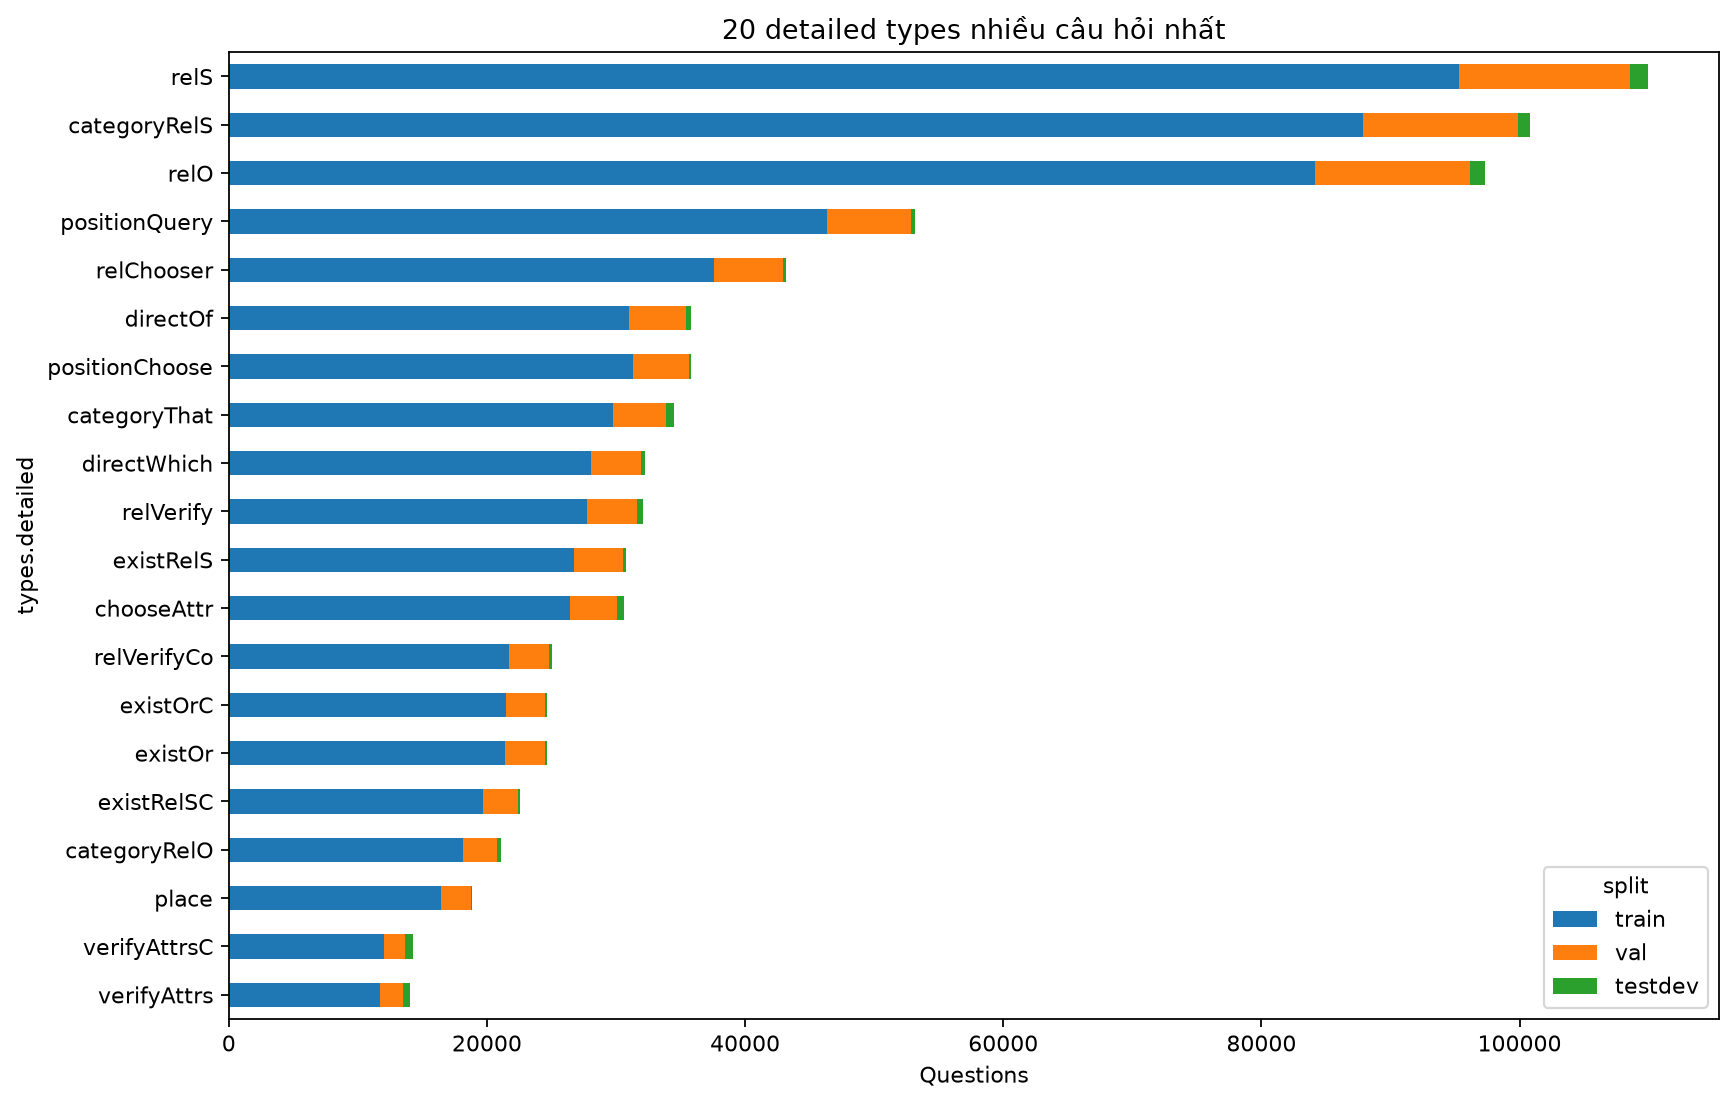

In [3]:
top = inventory.groupby('types_detailed')['count'].sum().nlargest(20).index
pivot = inventory[inventory.types_detailed.isin(top)].pivot_table(
    index='types_detailed', columns='split', values='count', aggfunc='sum', fill_value=0
).reindex(top).reindex(columns=['train', 'val', 'testdev'], fill_value=0)
ax = pivot.iloc[::-1].plot.barh(stacked=True, figsize=(11, 7), title='20 detailed types nhiều câu hỏi nhất')
ax.set(xlabel='Questions', ylabel='types.detailed')
plt.tight_layout(); plt.show()


## Thành phần đáp án theo loại câu hỏi


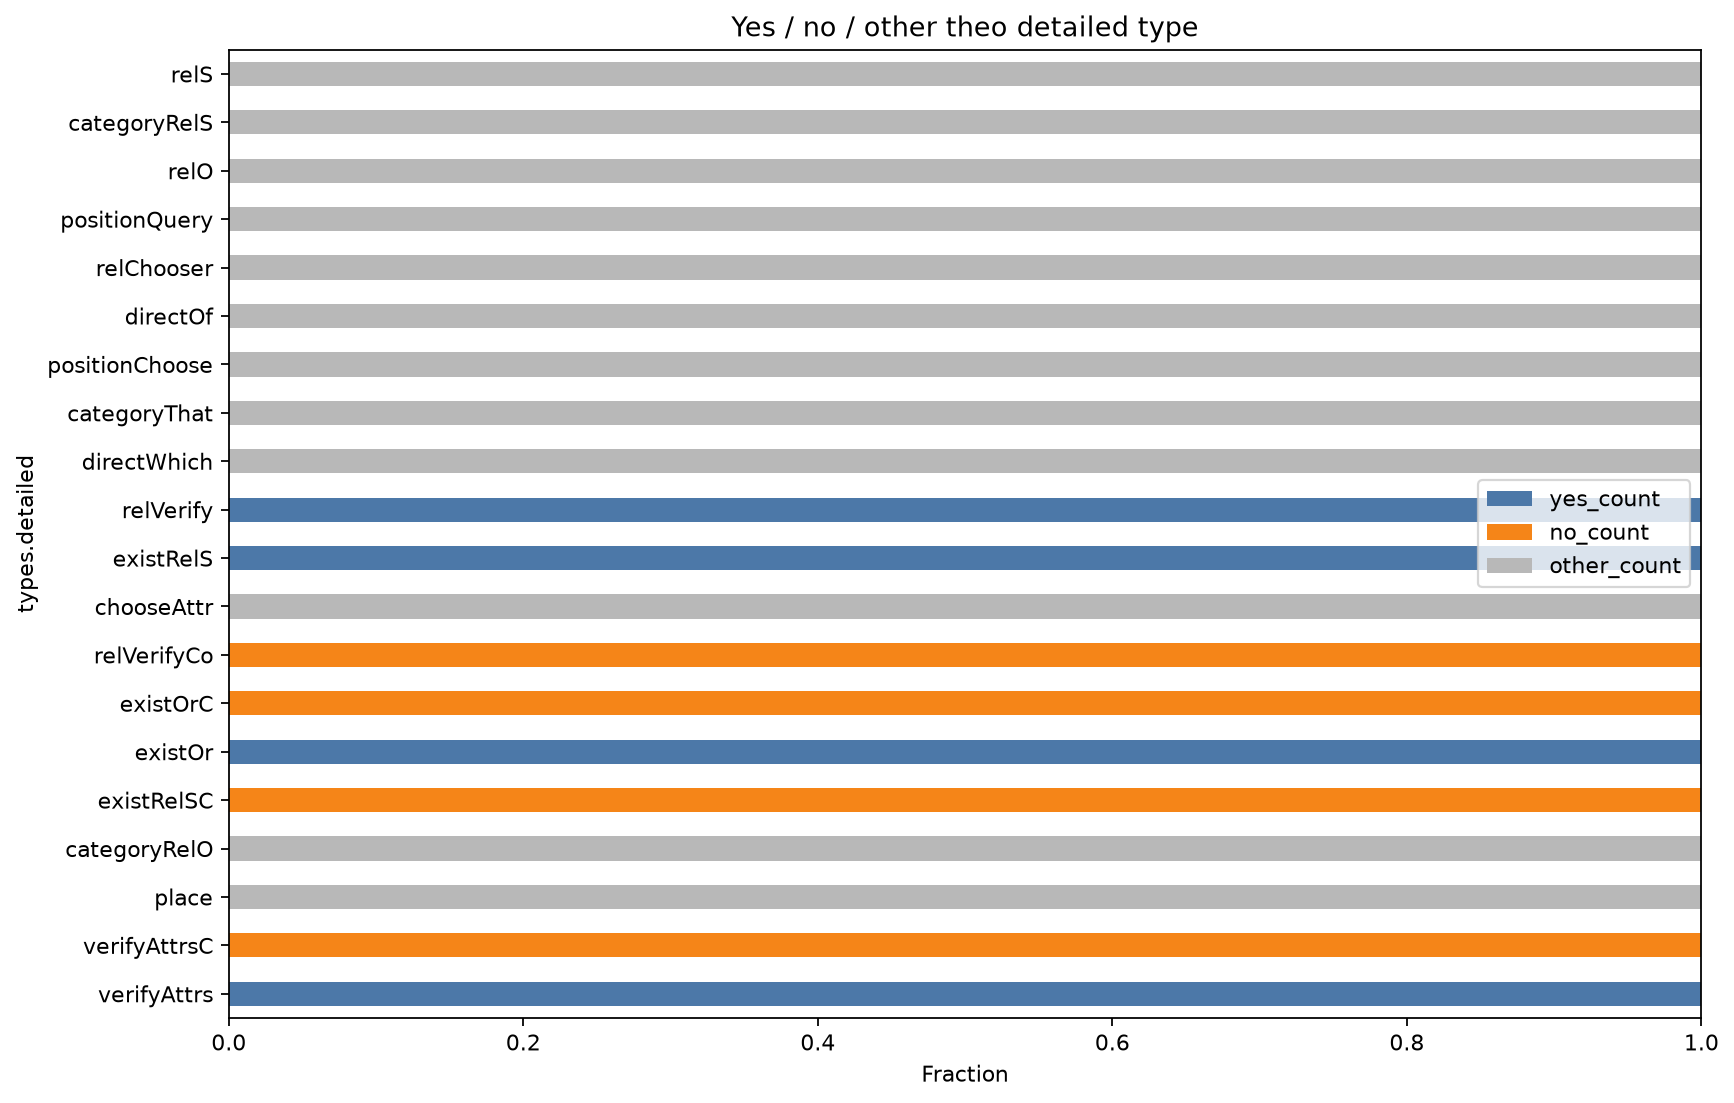

In [4]:
answers = inventory.groupby('types_detailed')[['yes_count', 'no_count', 'other_count']].sum().loc[top]
fractions = answers.div(answers.sum(axis=1), axis=0)
ax = fractions.iloc[::-1].plot.barh(stacked=True, figsize=(11, 7), title='Yes / no / other theo detailed type')
ax.set(xlabel='Fraction', ylabel='types.detailed', xlim=(0, 1))
plt.tight_layout(); plt.show()


## Các thao tác trong chương trình suy luận


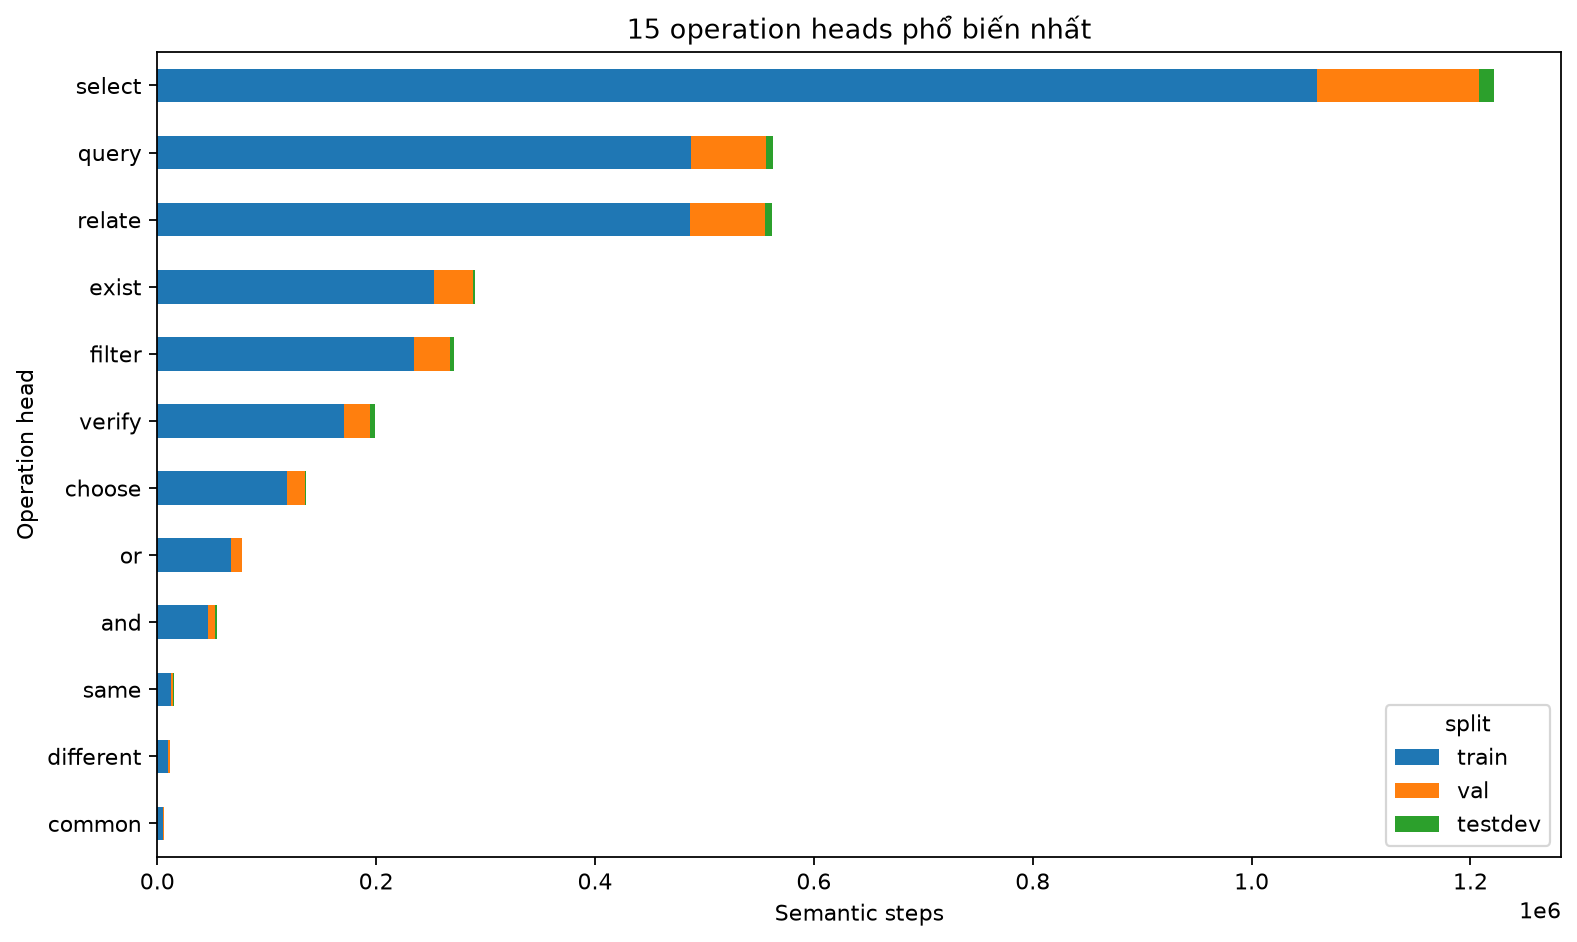

In [5]:
head_counts = operations.drop_duplicates(['split', 'head'])
head_top = head_counts.groupby('head')['head_count'].sum().nlargest(15).index
head_pivot = head_counts[head_counts['head'].isin(head_top)].pivot_table(
    index='head', columns='split', values='head_count', aggfunc='sum', fill_value=0
).reindex(head_top).reindex(columns=['train', 'val', 'testdev'], fill_value=0)
ax = head_pivot.iloc[::-1].plot.barh(stacked=True, figsize=(10, 6), title='15 operation heads phổ biến nhất')
ax.set(xlabel='Semantic steps', ylabel='Operation head')
plt.tight_layout(); plt.show()


## Ảnh hưởng của bộ lọc relation

Mẫu số là câu hỏi yes/no có chương trình không rỗng trong các nhóm dự kiến. Các con số này chỉ hỗ trợ duyệt quy tắc; chưa chọn định nghĩa chính thức.


In [6]:
impact = candidates.groupby('task')[['eligible_yesno_nonempty', 'R_strict_removed', 'R_broad_removed']].sum()
impact = impact.loc[[task for task in ['exist', 'verifyAttr', 'compare'] if task in impact.index]]
print(impact.to_string())


            eligible_yesno_nonempty  R_strict_removed  R_broad_removed
task                                                                  
exist                             0                 0                0
verifyAttr                        0                 0                0
compare                           0                 0                0


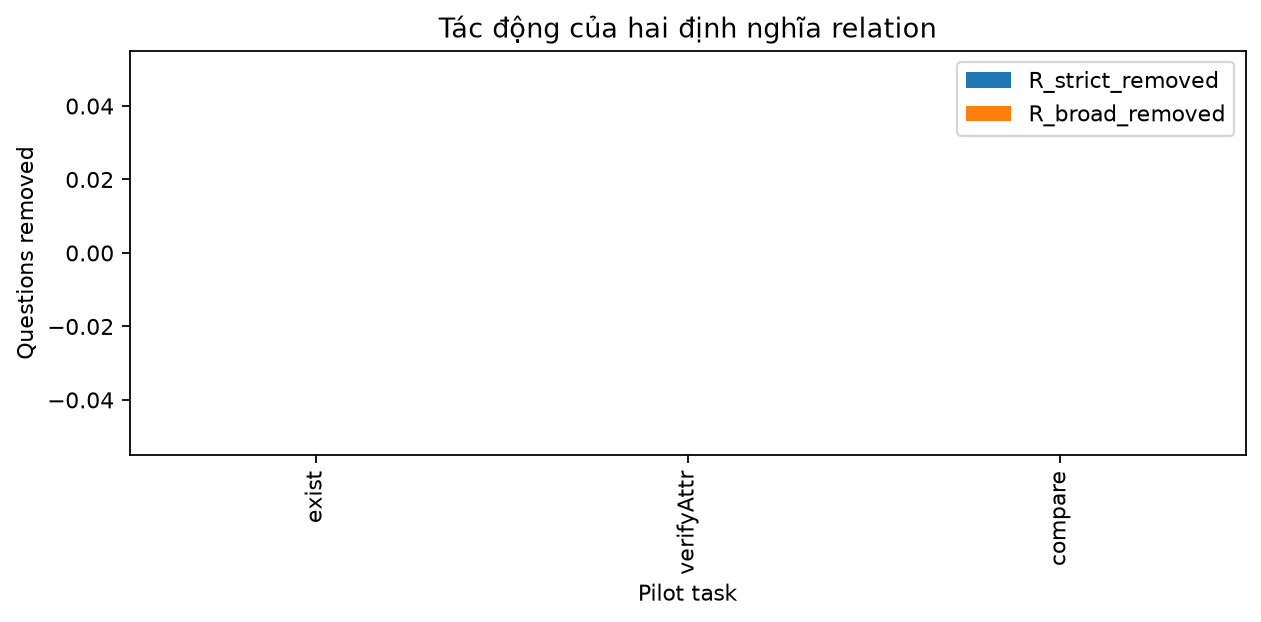

In [7]:
ax = impact[['R_strict_removed', 'R_broad_removed']].plot.bar(figsize=(8, 4), title='Tác động của hai định nghĩa relation')
ax.set(xlabel='Pilot task', ylabel='Questions removed')
plt.tight_layout(); plt.show()


## Tệp để duyệt

- `gqa_audit/config/task_rules.PROPOSED.yaml`
- `gqa_audit/config/op_family_map.PROPOSED.yaml`
- `gqa_audit/outputs/stage1/STAGE1_SUMMARY.md`
- `gqa_audit/outputs/stage1/relation_matches.csv`

**Dừng tại đây để người nghiên cứu duyệt.**
